# Annual PM2.5 in California · 2024

**How much fine particulate matter was present, averaged across the state’s area?** The research run gave **6.1139 µg/m³** across **409,583.9 km²** of valid grid coverage. These are reference values from the original calculation. The cells below independently rebuild California’s weights from the input geometry and compare the result.

**Inputs** • The 2024 global CNN V6.GL.03 annual PM2.5 NetCDF on the 0.1° grid and the GADM 4.1 ADM1 GeoPackage used in the original run. Use the annual global file even though the example selects a single state. Different boundary or grid versions can give different results.

**Run locally** • Place the project’s reviewed `aggregation.py` beside this notebook. Open the notebook with the project's geospatial Jupyter kernel. For a fresh environment, install `jupyterlab xarray netcdf4 geopandas pyogrio shapely pyproj numpy matplotlib` from conda-forge. Supply local paths at the two prompts, then run all cells in order. The example builds weights in memory and writes no data or caches.

In [1]:
# CONFIG — choose the two inputs for the California 2024 example
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyogrio
import xarray as xr

import aggregation as agg

print("Paste the path as plain text without quotation marks.")
pm_file = Path(input("2024 annual global PM2.5 NetCDF path: ").strip()).expanduser()
boundary_file = Path(input("ADM1 GeoPackage path: ").strip()).expanduser()
# The research GeoPackage contains one layer. Set this for a multilayer file.
boundary_layer = None
cell_size = 0.1  # degrees between adjacent cell centers
area_crs = "EPSG:5070"  # CONUS Albers equal-area projection, in metres

## PROCESS · From grid cells to one state mean

Each weight is the area of a grid cell **inside California**. The module clips cells in longitude and latitude and measures the pieces in an equal-area projection. The state mean is the sum of concentration × overlap area divided by the sum of overlap areas with valid concentrations. A missing concentration contributes to neither sum.

In [2]:
# PROCESS — read California and the annual concentration grid
layers = pyogrio.list_layers(boundary_file)[:, 0]
if boundary_layer is None and len(layers) != 1:
    raise ValueError(f"Set boundary_layer in CONFIG to one of {list(layers)}.")
layer = layers[0] if boundary_layer is None else boundary_layer
region = agg.read_one_adm1(boundary_file, layer, "VARNAME_1", "CA|Calif.")

with xr.open_dataset(pm_file) as ds:
    grid = ds["PM25"].transpose("lat", "lon").load()

# The module constructs boxes on a 0.1° grid with edges at multiples of 0.1°.
for axis in ("lat", "lon"):
    centers = grid[axis].values.astype(float)
    if not np.allclose(np.abs(np.diff(centers)), cell_size, atol=2e-5):
        raise ValueError(f"Unexpected spacing on {axis}. Check the input product.")
    edges = centers - cell_size / 2
    if not np.allclose(edges, np.round(edges / cell_size) * cell_size, rtol=0, atol=2e-5):
        raise ValueError(f"Unexpected cell alignment on {axis}.")

clean_grid = agg.clean_pm25(grid, missing_value=-999)
weights = agg.build_overlap_weights(region, clean_grid, cell_size, area_crs)
result = agg.summarize_one_year(clean_grid, weights)

In [3]:
# CHECK — compare with the rounded research benchmarks
mean = result["mean_pm25"]
area = result["valid_area_km2"]
coverage = result["valid_fraction_of_footprint"]
if not (0 < area <= result["footprint_area_km2"] and 0 < coverage <= 1):
    raise ValueError("Check the grid footprint and valid overlap areas.")

print(f"California 2024 area-weighted PM2.5: {mean:.4f} µg/m³")
print(f"Valid overlap: {area:,.1f} km² ({coverage:.1%} of grid overlap)")
# Tolerances reflect the rounding of the reported mean and area.
np.testing.assert_allclose(mean, 6.1139, rtol=0, atol=0.00005)
np.testing.assert_allclose(area, 409583.9, rtol=0, atol=0.05)

California 2024 area-weighted PM2.5: 6.1139 µg/m³
Valid overlap: 409,583.9 km² (100.0% of grid overlap)


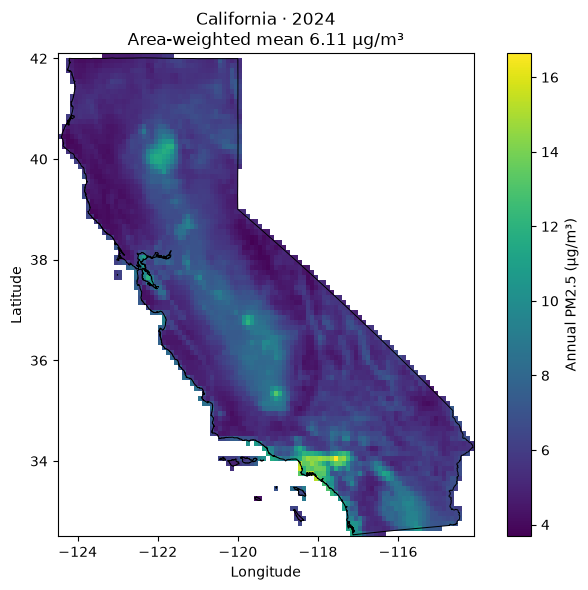

In [4]:
# INSPECT — map the annual grid cells used in the state calculation
rows = weights["row"].to_numpy(dtype=int)
cols = weights["col"].to_numpy(dtype=int)
# Crop the display to California and mask cells with no positive intersection.
lat_slice = slice(rows.min(), rows.max() + 1)
lon_slice = slice(cols.min(), cols.max() + 1)
subset = clean_grid.isel(lat=lat_slice, lon=lon_slice)
inside = np.zeros(subset.shape, dtype=bool)
inside[rows - rows.min(), cols - cols.min()] = True

fig, ax = plt.subplots(figsize=(7, 6))
subset.where(inside).plot.pcolormesh(
    ax=ax, x="lon", y="lat", cmap="viridis",
    cbar_kwargs={"label": "Annual PM2.5 (µg/m³)"},
)
region.boundary.plot(ax=ax, color="black", linewidth=0.7)
ax.set(title=f"California · 2024\nArea-weighted mean {mean:.2f} µg/m³",
       xlabel="Longitude", ylabel="Latitude")
plt.tight_layout()
plt.show()

The outline marks the ADM1 boundary. Each colored square shows a source-cell concentration. Edge squares appear at their full display size, although only the clipped area contributes to the reported mean. Blank areas inside the outline lack a valid concentration. The percentage above uses the grid overlap as its denominator. This summary describes geographic area and does not estimate average exposure per person.